In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directoryq
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/flipkart-fasion-products-dataset/output.xlsx
/kaggle/input/flipkart-fasion-products-dataset/flipkart_fashion_products_dataset.json


# Importing the datasets 

In [2]:
output_df = pd.read_excel('/kaggle/input/flipkart-fasion-products-dataset/output.xlsx')

In [3]:
output_df.head()

,Unnamed: 0,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,"02/10/2021, 20:11:51",69% off,Yorker trackpants made from 100% rich combed c...,['https://rukminim1.flixcart.com/image/128/128...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,"02/10/2021, 20:11:52",66% off,Yorker trackpants made from 100% rich combed c...,['https://rukminim1.flixcart.com/image/128/128...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,"02/10/2021, 20:11:52",68% off,Yorker trackpants made from 100% rich combed c...,['https://rukminim1.flixcart.com/image/128/128...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,"2,999",3.9,York,Clothing and Accessories,"02/10/2021, 20:11:53",69% off,Yorker trackpants made from 100% rich combed c...,['https://rukminim1.flixcart.com/image/128/128...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,4,750caa3d-6264-53ca-8ce1-94118a1d8951,"2,999",3.9,York,Clothing and Accessories,"02/10/2021, 20:11:53",68% off,Yorker trackpants made from 100% rich combed c...,['https://rukminim1.flixcart.com/image/128/128...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943,Bottomwear,"Solid Men Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...


In [4]:
output_df.shape

(30000, 18)

In [5]:
fp_data = pd.read_json('/kaggle/input/flipkart-fasion-products-dataset/flipkart_fashion_products_dataset.json')

# /kaggle/input/flipkart-fasion-products-dataset/flipkart_fashion_products_dataset.json

In [6]:
fp_data.head()

,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,750caa3d-6264-53ca-8ce1-94118a1d8951,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943,Bottomwear,"Solid Men Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...


In [7]:
## Both the datasets are the same and hence we will proceed with the output_df data 

# Exploring the dataset

In [8]:
output_df.columns

Index(['Unnamed: 0', '_id', 'actual_price', 'average_rating', 'brand',
       'category', 'crawled_at', 'description', 'discount', 'images',
       'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price',
       'sub_category', 'title', 'url'],
      dtype='object')

In [9]:
output_df = output_df.drop(['Unnamed: 0', '_id','description','images' , 'url','pid'], axis = 1)
# Looking into the data types
output_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   actual_price     29137 non-null  object 
 1   average_rating   27554 non-null  float64
 2   brand            27932 non-null  object 
 3   category         30000 non-null  object 
 4   crawled_at       30000 non-null  object 
 5   discount         18017 non-null  object 
 6   out_of_stock     30000 non-null  bool   
 7   product_details  30000 non-null  object 
 8   seller           28259 non-null  object 
 9   selling_price    29998 non-null  object 
 10  sub_category     30000 non-null  object 
 11  title            30000 non-null  object 
dtypes: bool(1), float64(1), object(10)
memory usage: 2.5+ MB


In [10]:
## Converting the data into appropriate type
output_df['actual_price'] = output_df['actual_price'].str.replace(',','')
output_df['selling_price'] = output_df['selling_price'].str.replace(',','')
output_df[['actual_price','selling_price']] = output_df[['actual_price','selling_price']].apply(pd.to_numeric)


In [11]:
## Creating a function to look into the missing , duplicate and unique values of individual columns

def data(df):
    missing_values = df.isnull().sum()
    duplicated_rows = df.duplicated().sum()
    unique_values = df.nunique()
    
    
    object = pd.DataFrame({
        "Missing values ": missing_values,
        "Duplcaited values ": duplicated_rows,
        "Unique values": unique_values
    })
    
    return object




data(output_df)

,Missing values,Duplcaited values,Unique values
actual_price,863,222,728
average_rating,2446,222,38
brand,2068,222,324
category,0,222,4
crawled_at,0,222,17188
discount,11983,222,5192
out_of_stock,0,222,2
product_details,0,222,26783
seller,1741,222,534
selling_price,2,222,1512


In [12]:
output_df.head()

,actual_price,average_rating,brand,category,crawled_at,discount,out_of_stock,product_details,seller,selling_price,sub_category,title
0,2999.0,3.9,York,Clothing and Accessories,"02/10/2021, 20:11:51",Yorker trackpants made from 100% rich combed c...,False,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921.0,Bottomwear,Solid Men Multicolor Track Pants
1,1499.0,3.9,York,Clothing and Accessories,"02/10/2021, 20:11:52",Yorker trackpants made from 100% rich combed c...,False,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499.0,Bottomwear,Solid Men Blue Track Pants
2,2999.0,3.9,York,Clothing and Accessories,"02/10/2021, 20:11:52",Yorker trackpants made from 100% rich combed c...,False,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931.0,Bottomwear,Solid Men Multicolor Track Pants
3,2999.0,3.9,York,Clothing and Accessories,"02/10/2021, 20:11:53",Yorker trackpants made from 100% rich combed c...,False,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911.0,Bottomwear,Solid Men Multicolor Track Pants
4,2999.0,3.9,York,Clothing and Accessories,"02/10/2021, 20:11:53",Yorker trackpants made from 100% rich combed c...,False,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943.0,Bottomwear,"Solid Men Brown, Grey Track Pants"


# Looking into the Category and subcategory

<Axes: xlabel='category', ylabel='count'>

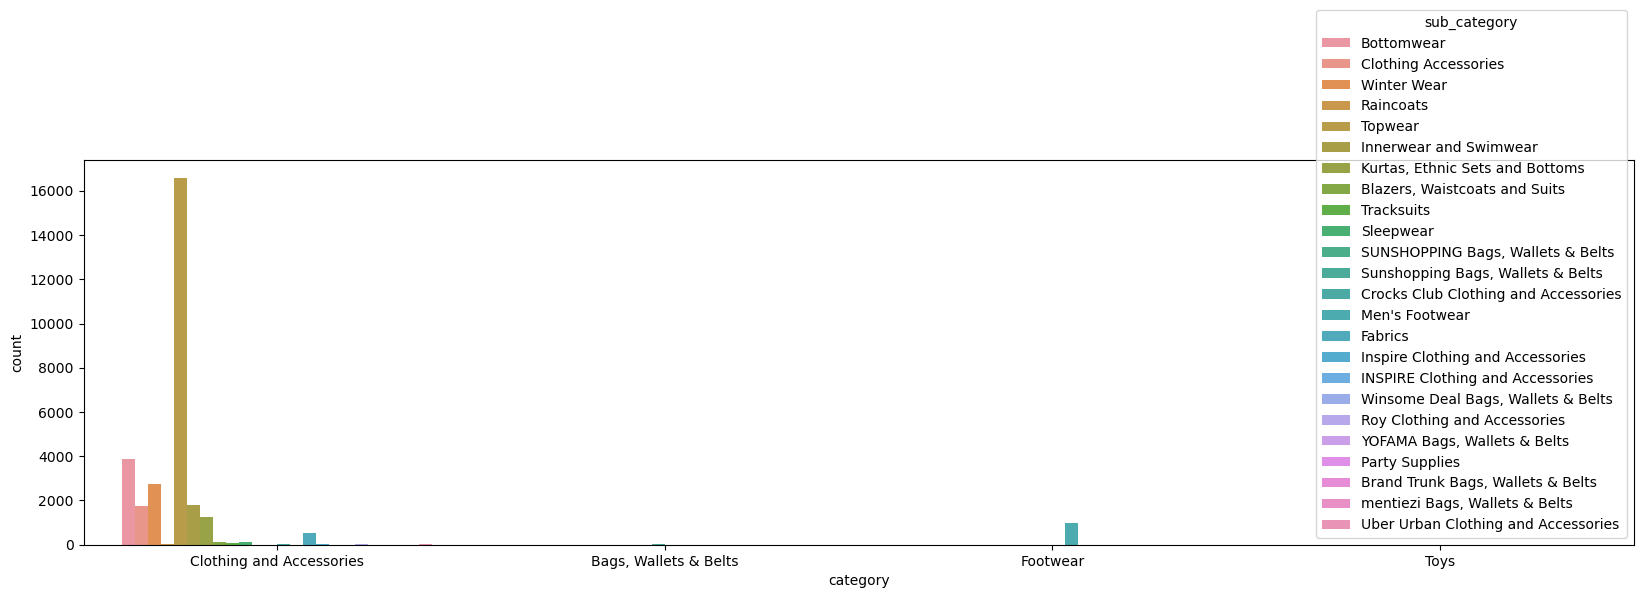

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure(figsize=(20,5))
sns.countplot(data = output_df , x = 'category' ,hue = 'sub_category' )

In [14]:
def plot(df , figsize , subplot):
    
    plt.figure(figsize = figsize)
    for index , column in enumerate(df.columns):
        plt.subplot(*subplot , index+1)
        sns.histplot(df[column])
        plt.xticks(rotation = 'vertical')
        
    

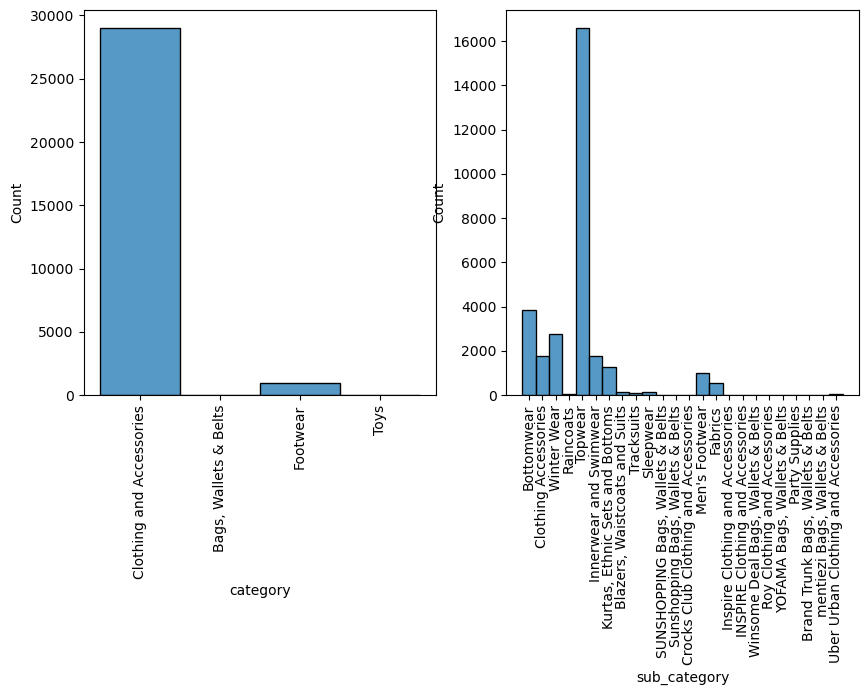

In [15]:
plot(output_df[['category','sub_category']],(10,5),(1,2))

# Most-Valued Brand and OutOfStock Information 

/tmp/ipykernel_20/2079061597.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_brand_stock = df_brand_stock.groupby('brand').sum().reset_index()


<Axes: xlabel='brand', ylabel='selling_price'>

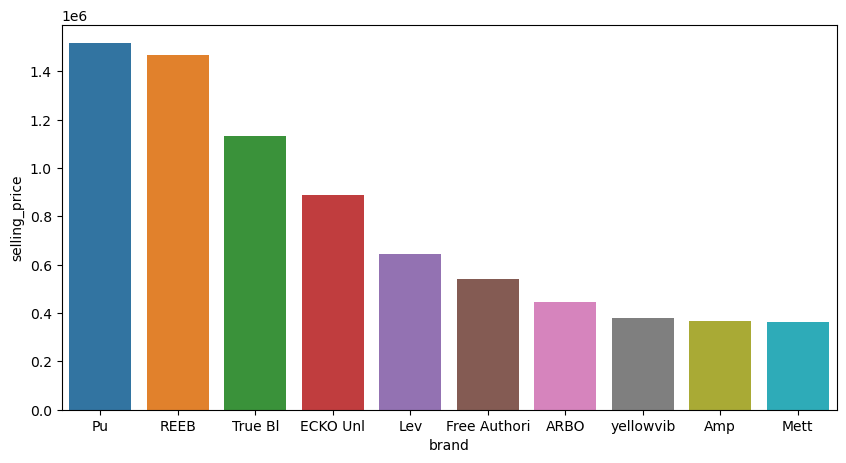

In [16]:
df_brand_stock = output_df.loc[:,['brand','out_of_stock','title','selling_price']]
df_brand_stock = df_brand_stock.groupby('brand').sum().reset_index()
df_brand_stock.sort_values(by = 'selling_price',ascending = False ,inplace = True)
df_brand_stock = df_brand_stock.head(10)
plt.figure(figsize = (10,5))
sns.barplot(data = df_brand_stock , x = 'brand' ,y = 'selling_price')

In [17]:
df_brand_count = output_df.loc[:,['brand','out_of_stock','title','selling_price']]
df_brand_count['out_of_stock'] = df_brand_count['out_of_stock'].astype(str)
df_brand_count['out_of_stock'] = df_brand_count['out_of_stock'].str.replace('False','0')
df_brand_count['out_of_stock'] = df_brand_count['out_of_stock'].str.replace('True','1')
df_brand_count['out_of_stock'] = df_brand_count['out_of_stock'].astype('int')
df_brand_count = df_brand_count.groupby('brand').sum().reset_index()
df_brand_count.sort_values(by = 'out_of_stock' ,  ascending = False  , inplace = True )
df_brand_count = df_brand_count.head(10)

/tmp/ipykernel_20/1558163653.py:6: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_brand_count = df_brand_count.groupby('brand').sum().reset_index()


<Axes: xlabel='selling_price', ylabel='out_of_stock'>

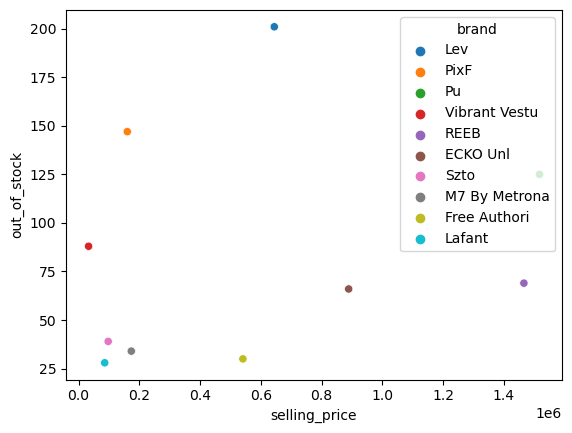

In [18]:
sns.scatterplot(data = df_brand_count , x = 'selling_price' , y = 'out_of_stock' , hue = 'brand')

In [19]:
df_brand_count.sort_values(by = 'out_of_stock' ,ascending = False,inplace = True )


# Seller Information 

In [20]:
df_seller_stock = output_df.loc[:,['brand','out_of_stock','selling_price','seller']]
df_seller_stock = df_seller_stock.groupby('seller').sum().reset_index()
df_seller_stock1 = df_seller_stock.sort_values(by = 'selling_price',ascending = False)
df_seller_stock_top10 = df_seller_stock.head(10)
df_seller_stock2 =  df_seller_stock.sort_values(by = 'out_of_stock',ascending = False)
df_seller_stock2_top10 = df_seller_stock2.head(10)

/tmp/ipykernel_20/1671903140.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_seller_stock = df_seller_stock.groupby('seller').sum().reset_index()


(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, '3KD Fashion'),
  Text(1, 0, 'A D ENTERPRISES2020'),
  Text(2, 0, 'A D ENTERPRISES20204.1Seller changed. Check for any changes in pricing and related informatio'),
  Text(3, 0, 'A ONE QUALITY'),
  Text(4, 0, 'AALAE'),
  Text(5, 0, 'AASHRAY SPORTS'),
  Text(6, 0, 'AB INTERNATIONAL(Not Enough Ratin'),
  Text(7, 0, 'ABCGARMENTS'),
  Text(8, 0, 'ADITYA  TEX'),
  Text(9, 0, 'AFFGARMENTS')])

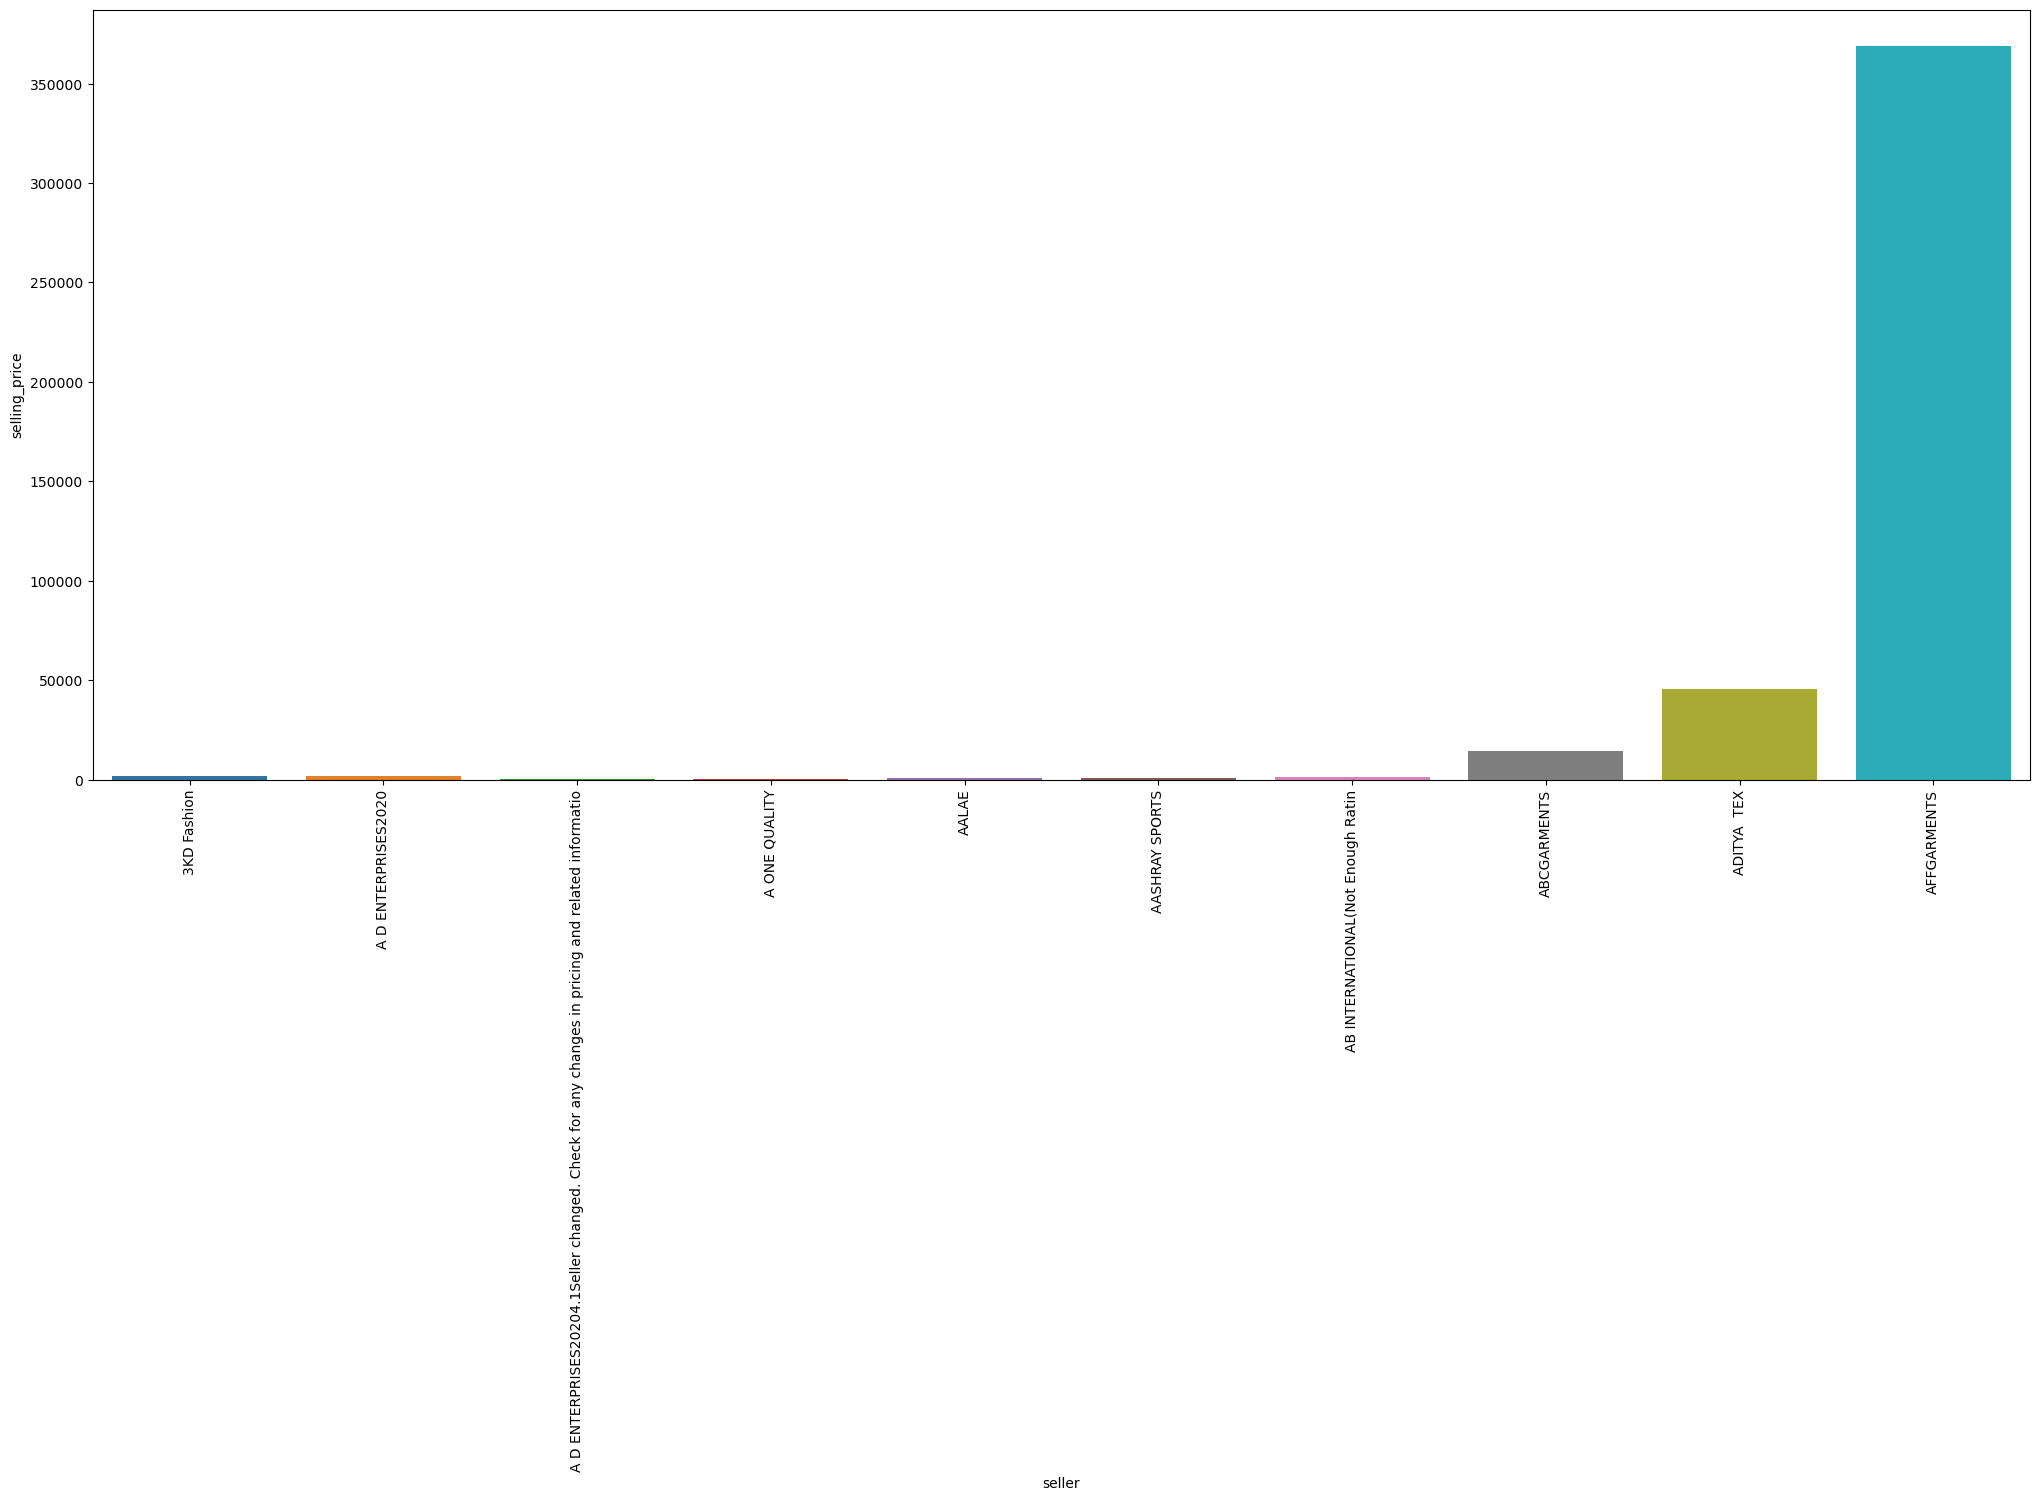

In [21]:
 # Creating 2 subplots
plt.figure(figsize = (25,10))

    
# Accessing each axes object to plot the data through returned array
sns.barplot(data = df_seller_stock_top10,x= df_seller_stock_top10['seller'],y = df_seller_stock_top10['selling_price'])
plt.xticks(rotation = 'vertical')

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'RetailNet'),
  Text(1, 0, 'RetailNet4.5Seller changed. Check for any changes in pricing and related informatio'),
  Text(2, 0, 'SELVAMANITEX'),
  Text(3, 0, 'SELLNETRETA'),
  Text(4, 0, 'SELECTAIRE (New Sell'),
  Text(5, 0, 'SDK RETAIL ENTERPRISES(New Sell'),
  Text(6, 0, 'SANEFASHIONS'),
  Text(7, 0, 'SAINISTORES(Not Enough Ratin'),
  Text(8, 0, 'SAGUNCOLLECTION(New Sell'),
  Text(9, 0, 'SAANVIICREATION')])

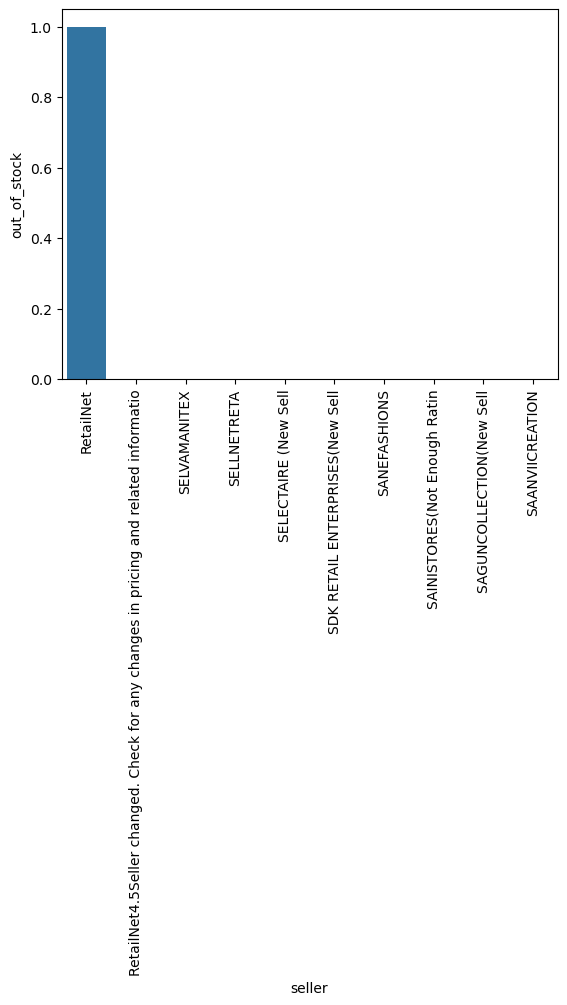

In [22]:
sns.barplot(data = df_seller_stock2_top10 ,x = df_seller_stock2_top10['seller'],y = df_seller_stock2_top10['out_of_stock'])
plt.xticks(rotation = 'vertical')